# Multi-Asset Portfolio Analytics Platform

## Part 1: Data Collection

This project analyzes portfolio construction and risk across a diversified
multi-asset institutional investment mandate.

### Portfolio Strategies
- Equal Weight
- Minimum Variance
- Maximum Sharpe
- Risk Parity

### Risk Analytics
- Value at Risk (VaR)
- Conditional Value at Risk (CVaR)
- Maximum Drawdown
- Monte Carlo Stress Testing

In [6]:
# ============================================================
# MULTI-ASSET PORTFOLIO ANALYTICS PLATFORM
# Part 1: Data Collection
# ============================================================

# Import numerical analysis library
import numpy as np

# Import data manipulation library
import pandas as pd

# Import visualization library
import matplotlib.pyplot as plt

# Import market data library
import yfinance as yf

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [7]:

# Define the Multi-Asset Investment Universe


assets = {
    "SPY": "US Equities",
    "VXUS": "International Equities",
    "VWO": "Emerging Markets",
    "IEF": "US Treasuries",
    "LQD": "Investment Grade Bonds",
    "VNQ": "US REITs",
    "GLD": "Gold",
    "SHY": "Short-Term Treasuries"
}

print("Number of assets:", len(assets))
print("\nInvestment Universe:")

for ticker, asset_class in assets.items():
    print(f"{ticker}: {asset_class}")

Number of assets: 8

Investment Universe:
SPY: US Equities
VXUS: International Equities
VWO: Emerging Markets
IEF: US Treasuries
LQD: Investment Grade Bonds
VNQ: US REITs
GLD: Gold
SHY: Short-Term Treasuries


In [8]:
# Creating a list of ticker symbols

tickers = list(assets.keys())

print(tickers)

['SPY', 'VXUS', 'VWO', 'IEF', 'LQD', 'VNQ', 'GLD', 'SHY']


In [9]:
# Download Historical Market Data

prices = yf.download(
    tickers,
    start="2015-01-01",
    end="2026-01-01",
    auto_adjust=True
)

print(prices.head())

[*********************100%***********************]  8 of 8 completed

Price            Close                                               \
Ticker             GLD        IEF        LQD        SHY         SPY   
Date                                                                  
2015-01-02  114.080002  81.743942  79.445389  68.078468  169.267502   
2015-01-05  115.800003  82.242714  79.770294  68.078468  166.210587   
2015-01-06  117.120003  82.795212  80.095085  68.110710  164.645065   
2015-01-07  116.430000  82.779800  80.201187  68.142914  166.696686   
2015-01-08  115.940002  82.442223  79.942627  68.134857  169.654755   

Price                                              High             ...  \
Ticker            VNQ        VWO       VXUS         GLD        IEF  ...   
Date                                                                ...   
2015-01-02  51.642834  28.555986  34.354355  114.800003  81.843699  ...   
2015-01-05  51.925491  28.101238  33.599014  116.000000  82.296427  ...   
2015-01-06  52.440536  27.964083  33.342472  117.500000 

In [10]:
# Calculate Daily Returns

returns = prices["Close"].pct_change()

print(returns.head())

Ticker           GLD       IEF       LQD       SHY       SPY       VNQ  \
Date                                                                     
2015-01-02       NaN       NaN       NaN       NaN       NaN       NaN   
2015-01-05  0.015077  0.006102  0.004090  0.000000 -0.018060  0.005473   
2015-01-06  0.011399  0.006718  0.004072  0.000474 -0.009419  0.009919   
2015-01-07 -0.005891 -0.000186  0.001325  0.000473  0.012461  0.015331   
2015-01-08 -0.004209 -0.004078 -0.003224 -0.000118  0.017745  0.003775   

Ticker           VWO      VXUS  
Date                            
2015-01-02       NaN       NaN  
2015-01-05 -0.015925 -0.021987  
2015-01-06 -0.004881 -0.007635  
2015-01-07  0.022974  0.011755  
2015-01-08  0.016906  0.012674  


In [11]:
# Clean the Return Data

returns = returns.dropna()

print(returns.head())

Ticker           GLD       IEF       LQD       SHY       SPY       VNQ  \
Date                                                                     
2015-01-05  0.015077  0.006102  0.004090  0.000000 -0.018060  0.005473   
2015-01-06  0.011399  0.006718  0.004072  0.000474 -0.009419  0.009919   
2015-01-07 -0.005891 -0.000186  0.001325  0.000473  0.012461  0.015331   
2015-01-08 -0.004209 -0.004078 -0.003224 -0.000118  0.017745  0.003775   
2015-01-09  0.011385  0.004933  0.002654  0.000827 -0.008014  0.000470   

Ticker           VWO      VXUS  
Date                            
2015-01-05 -0.015925 -0.021987  
2015-01-06 -0.004881 -0.007635  
2015-01-07  0.022974  0.011755  
2015-01-08  0.016906  0.012674  
2015-01-09 -0.004963 -0.004172  


In [12]:
# Basic Return Statistics

summary_stats = pd.DataFrame({
    "Average Daily Return": returns.mean(),
    "Daily Volatility": returns.std()
})

print(summary_stats)

        Average Daily Return  Daily Volatility
Ticker                                        
GLD                 0.000494          0.009290
IEF                 0.000058          0.004178
LQD                 0.000121          0.005324
SHY                 0.000063          0.000954
SPY                 0.000564          0.011208
VNQ                 0.000269          0.012920
VWO                 0.000304          0.012323
VXUS                0.000340          0.010785


In [13]:

# Annualized Return and Volatility

trading_days = 252

annualized_return = returns.mean() * trading_days
annualized_volatility = returns.std() * np.sqrt(trading_days)

annualized_stats = pd.DataFrame({
    "Annualized Return": annualized_return,
    "Annualized Volatility": annualized_volatility
})

print(annualized_stats)

        Annualized Return  Annualized Volatility
Ticker                                          
GLD              0.124400               0.147472
IEF              0.014593               0.066330
LQD              0.030561               0.084517
SHY              0.015832               0.015141
SPY              0.142186               0.177925
VNQ              0.067784               0.205097
VWO              0.076619               0.195629
VXUS             0.085790               0.171211


In [14]:
# Correlation Matrix

correlation_matrix = returns.corr()

print(correlation_matrix)

Ticker       GLD       IEF       LQD       SHY       SPY       VNQ       VWO  \
Ticker                                                                         
GLD     1.000000  0.354177  0.314891  0.354858  0.044217  0.131471  0.162265   
IEF     0.354177  1.000000  0.715450  0.803742 -0.160600  0.076310 -0.119985   
LQD     0.314891  0.715450  1.000000  0.540016  0.269753  0.391661  0.232450   
SHY     0.354858  0.803742  0.540016  1.000000 -0.082596  0.112730 -0.040562   
SPY     0.044217 -0.160600  0.269753 -0.082596  1.000000  0.724626  0.745216   
VNQ     0.131471  0.076310  0.391661  0.112730  0.724626  1.000000  0.545670   
VWO     0.162265 -0.119985  0.232450 -0.040562  0.745216  0.545670  1.000000   
VXUS    0.163691 -0.120526  0.282894 -0.029448  0.853068  0.659978  0.906366   

Ticker      VXUS  
Ticker            
GLD     0.163691  
IEF    -0.120526  
LQD     0.282894  
SHY    -0.029448  
SPY     0.853068  
VNQ     0.659978  
VWO     0.906366  
VXUS    1.000000  


In [15]:
# Covariance Matrix

covariance_matrix = returns.cov() * 252

print(covariance_matrix)

Ticker       GLD       IEF       LQD       SHY       SPY       VNQ       VWO  \
Ticker                                                                         
GLD     0.021748  0.003464  0.003925  0.000792  0.001160  0.003976  0.004681   
IEF     0.003464  0.004400  0.004011  0.000807 -0.001895  0.001038 -0.001557   
LQD     0.003925  0.004011  0.007143  0.000691  0.004056  0.006789  0.003843   
SHY     0.000792  0.000807  0.000691  0.000229 -0.000223  0.000350 -0.000120   
SPY     0.001160 -0.001895  0.004056 -0.000223  0.031657  0.026443  0.025939   
VNQ     0.003976  0.001038  0.006789  0.000350  0.026443  0.042065  0.021894   
VWO     0.004681 -0.001557  0.003843 -0.000120  0.025939  0.021894  0.038271   
VXUS    0.004133 -0.001369  0.004094 -0.000076  0.025987  0.023175  0.030358   

Ticker      VXUS  
Ticker            
GLD     0.004133  
IEF    -0.001369  
LQD     0.004094  
SHY    -0.000076  
SPY     0.025987  
VNQ     0.023175  
VWO     0.030358  
VXUS    0.029313  


In [16]:
# Equal-Weight Portfolio

num_assets = len(tickers)

equal_weights = np.repeat(1 / num_assets, num_assets)

print("Number of assets:", num_assets)
print("Equal weights:", equal_weights)
print("Sum of weights:", equal_weights.sum())

Number of assets: 8
Equal weights: [0.125 0.125 0.125 0.125 0.125 0.125 0.125 0.125]
Sum of weights: 1.0


In [17]:

# Equal-Weight Portfolio Performance

portfolio_returns = returns @ equal_weights

portfolio_return = portfolio_returns.mean() * 252
portfolio_volatility = portfolio_returns.std() * np.sqrt(252)

print("Annualized Portfolio Return:", portfolio_return)
print("Annualized Portfolio Volatility:", portfolio_volatility)

Annualized Portfolio Return: 0.06972066015308244
Annualized Portfolio Volatility: 0.09417080184805858


In [18]:

import numpy as np
import pandas as pd
from scipy.optimize import minimize

print("Libraries imported successfully!")


Libraries imported successfully!


In [19]:

# ============================================================
# Minimum-Variance Portfolio Optimization
# ============================================================

from scipy.optimize import minimize

# Calculate portfolio volatility for any given weights
def calculate_portfolio_volatility(weights):
    portfolio_variance = weights.T @ covariance_matrix @ weights
    return np.sqrt(portfolio_variance)

# Initial portfolio weights
num_assets = len(returns.columns)
initial_weights = np.repeat(1 / num_assets, num_assets)

# All portfolio weights must add up to 100%
constraints = ({
    "type": "eq",
    "fun": lambda weights: np.sum(weights) - 1
})

# Each asset weight must be between 0% and 100%
bounds = tuple((0, 1) for _ in range(num_assets))

# Find minimum-variance portfolio
min_var_result = minimize(
    calculate_portfolio_volatility,
    initial_weights,
    method="SLSQP",
    bounds=bounds,
    constraints=constraints,
    options={"ftol": 1e-12, "maxiter": 1000}
)

if not min_var_result.success:
    raise RuntimeError(min_var_result.message)

# Extract optimal weights
min_var_weights = min_var_result.x

# Display results
print("Minimum-Variance Portfolio Weights:")

for ticker, weight in zip(returns.columns, min_var_weights):
    print(f"{ticker}: {weight:.2%}")

print("Total Weight:", f"{min_var_weights.sum():.2%}")
print("Annualized Volatility:",
      f"{calculate_portfolio_volatility(min_var_weights):.2%}")


Minimum-Variance Portfolio Weights:
GLD: 0.00%
IEF: 0.00%
LQD: 0.00%
SHY: 98.60%
SPY: 1.40%
VNQ: 0.00%
VWO: 0.00%
VXUS: 0.00%
Total Weight: 100.00%
Annualized Volatility: 1.49%


In [20]:

# ============================================================
# Minimum-Variance Portfolio Performance
# ============================================================

# Calculate daily portfolio returns
min_var_daily_returns = returns @ min_var_weights

# Calculate annualized return
min_var_return = min_var_daily_returns.mean() * 252

# Calculate annualized volatility
min_var_volatility = min_var_daily_returns.std() * np.sqrt(252)

# Display results
print("Minimum-Variance Portfolio Performance")
print("--------------------------------------")
print(f"Annualized Return: {min_var_return:.2%}")
print(f"Annualized Volatility: {min_var_volatility:.2%}")


Minimum-Variance Portfolio Performance
--------------------------------------
Annualized Return: 1.76%
Annualized Volatility: 1.49%


In [21]:

# ============================================================
# Portfolio Expected Return Function
# ============================================================

# Calculate annualized average returns for each ETF
expected_returns = returns.mean() * 252

# Function to calculate portfolio expected return
def calculate_portfolio_return(weights):
    return np.dot(weights, expected_returns)

# Test using our equal-weight portfolio
print("Equal-Weight Portfolio Return:",
      f"{calculate_portfolio_return(equal_weights):.2%}")


Equal-Weight Portfolio Return: 6.97%


In [22]:

# ============================================================
# Sharpe Ratio Function
# ============================================================

# Assumed annual risk-free rate
risk_free_rate = 0.02

# Function to calculate portfolio Sharpe ratio
def calculate_sharpe_ratio(weights):

    portfolio_return = calculate_portfolio_return(weights)

    portfolio_volatility = calculate_portfolio_volatility(weights)

    sharpe_ratio = (portfolio_return - risk_free_rate) / portfolio_volatility

    return sharpe_ratio

# Test using equal-weight portfolio
print("Equal-Weight Sharpe Ratio:",
      f"{calculate_sharpe_ratio(equal_weights):.4f}")


Equal-Weight Sharpe Ratio: 0.5280


In [23]:

# ============================================================
# Maximum-Sharpe Portfolio Optimization
# ============================================================

# Define the negative Sharpe ratio
def negative_sharpe_ratio(weights):
    return -calculate_sharpe_ratio(weights)

# Run portfolio optimization
max_sharpe_result = minimize(
    negative_sharpe_ratio,
    initial_weights,
    method="SLSQP",
    bounds=bounds,
    constraints=constraints,
    options={"ftol": 1e-12, "maxiter": 1000}
)

# Check whether optimization succeeded
if not max_sharpe_result.success:
    raise RuntimeError(max_sharpe_result.message)

# Extract optimal weights
max_sharpe_weights = max_sharpe_result.x

# Display results
print("Maximum-Sharpe Portfolio Weights:")
print("--------------------------------")

for ticker, weight in zip(returns.columns, max_sharpe_weights):
    print(f"{ticker}: {weight:.2%}")

print("Total Weight:", f"{max_sharpe_weights.sum():.2%}")

print("Maximum Sharpe Ratio:",
      f"{calculate_sharpe_ratio(max_sharpe_weights):.4f}")


Maximum-Sharpe Portfolio Weights:
--------------------------------
GLD: 55.50%
IEF: 0.00%
LQD: 0.00%
SHY: 0.00%
SPY: 44.50%
VNQ: 0.00%
VWO: 0.00%
VXUS: 0.00%
Total Weight: 100.00%
Maximum Sharpe Ratio: 0.9652


In [24]:

# ============================================================
# Maximum-Sharpe Portfolio Performance
# ============================================================

# Calculate daily portfolio returns
max_sharpe_daily_returns = returns @ max_sharpe_weights

# Calculate annualized portfolio return
max_sharpe_return = max_sharpe_daily_returns.mean() * 252

# Calculate annualized portfolio volatility
max_sharpe_volatility = max_sharpe_daily_returns.std() * np.sqrt(252)

# Calculate Sharpe ratio
max_sharpe_ratio = (
    max_sharpe_return - risk_free_rate
) / max_sharpe_volatility

# Display results
print("Maximum-Sharpe Portfolio Performance")
print("------------------------------------")
print(f"Annualized Return: {max_sharpe_return:.2%}")
print(f"Annualized Volatility: {max_sharpe_volatility:.2%}")
print(f"Sharpe Ratio: {max_sharpe_ratio:.4f}")

# ============================================================
# Maximum-Sharpe Portfolio Performance
# ============================================================

# Calculate daily portfolio returns
max_sharpe_daily_returns = returns @ max_sharpe_weights

# Calculate annualized portfolio return
max_sharpe_return = max_sharpe_daily_returns.mean() * 252

# Calculate annualized portfolio volatility
max_sharpe_volatility = max_sharpe_daily_returns.std() * np.sqrt(252)

# Calculate Sharpe ratio
max_sharpe_ratio = (
    max_sharpe_return - risk_free_rate
) / max_sharpe_volatility

# Display results
print("Maximum-Sharpe Portfolio Performance")
print("------------------------------------")
print(f"Annualized Return: {max_sharpe_return:.2%}")
print(f"Annualized Volatility: {max_sharpe_volatility:.2%}")
print(f"Sharpe Ratio: {max_sharpe_ratio:.4f}")


Maximum-Sharpe Portfolio Performance
------------------------------------
Annualized Return: 13.23%
Annualized Volatility: 11.64%
Sharpe Ratio: 0.9652
Maximum-Sharpe Portfolio Performance
------------------------------------
Annualized Return: 13.23%
Annualized Volatility: 11.64%
Sharpe Ratio: 0.9652


In [25]:

# ============================================================
# Portfolio Strategy Comparison
# ============================================================

portfolio_comparison = pd.DataFrame({
    "Portfolio": [
        "Equal Weight",
        "Minimum Variance",
        "Maximum Sharpe"
    ],

    "Annualized Return": [
        portfolio_return,
        min_var_return,
        max_sharpe_return
    ],

    "Annualized Volatility": [
        portfolio_volatility,
        min_var_volatility,
        max_sharpe_volatility
    ],

    "Sharpe Ratio": [
        calculate_sharpe_ratio(equal_weights),
        calculate_sharpe_ratio(min_var_weights),
        calculate_sharpe_ratio(max_sharpe_weights)
    ]
})

print(portfolio_comparison.to_string(index=False))


       Portfolio  Annualized Return  Annualized Volatility  Sharpe Ratio
    Equal Weight           0.069721               0.094171      0.527984
Minimum Variance           0.017598               0.014932     -0.160888
  Maximum Sharpe           0.132315               0.116365      0.965192


In [26]:

# ============================================================
# Risk Parity Portfolio - Risk Contributions
# ============================================================

def calculate_risk_contributions(weights):

    # Calculate total portfolio volatility
    portfolio_vol = calculate_portfolio_volatility(weights)

    # Calculate marginal contribution to portfolio risk
    marginal_risk = covariance_matrix @ weights / portfolio_vol

    # Calculate each asset's total risk contribution
    risk_contributions = weights * marginal_risk

    return risk_contributions


# Test using equal-weight portfolio
equal_risk_contributions = calculate_risk_contributions(equal_weights)

print("Equal-Weight Portfolio Risk Contributions:")
print("------------------------------------------")

for ticker, contribution in zip(returns.columns, equal_risk_contributions):
    print(f"{ticker}: {contribution:.4%}")

print("Total Portfolio Risk:",
      f"{equal_risk_contributions.sum():.4%}")


Equal-Weight Portfolio Risk Contributions:
------------------------------------------
GLD: 0.7281%
IEF: 0.1477%
LQD: 0.5733%
SHY: 0.0407%
SPY: 1.8770%
VNQ: 2.0861%
VWO: 2.0460%
VXUS: 1.9183%
Total Portfolio Risk: 9.4171%


In [27]:

# ============================================================
# Risk-Parity Portfolio Optimization
# ============================================================

# Function to measure differences in risk contributions
def risk_parity_objective(weights):

    # Calculate individual risk contributions
    risk_contributions = calculate_risk_contributions(weights)

    # Calculate total portfolio volatility
    total_risk = risk_contributions.sum()

    # Convert contributions into proportions of total risk
    risk_proportions = risk_contributions / total_risk

    # Target equal risk contribution for each asset
    target_risk = np.repeat(1 / num_assets, num_assets)

    # Measure squared differences from the target
    return np.sum((risk_proportions - target_risk) ** 2)


# Find risk-parity portfolio weights
risk_parity_result = minimize(
    risk_parity_objective,
    initial_weights,
    method="SLSQP",
    bounds=bounds,
    constraints=constraints,
    options={"ftol": 1e-12, "maxiter": 2000}
)

# Check optimization success
if not risk_parity_result.success:
    raise RuntimeError(risk_parity_result.message)

# Extract optimized weights
risk_parity_weights = risk_parity_result.x

# Display results
print("Risk-Parity Portfolio Weights:")
print("--------------------------------")

for ticker, weight in zip(returns.columns, risk_parity_weights):
    print(f"{ticker}: {weight:.2%}")

print("Total Weight:", f"{risk_parity_weights.sum():.2%}")


Risk-Parity Portfolio Weights:
--------------------------------
GLD: 6.16%
IEF: 13.50%
LQD: 7.76%
SHY: 56.78%
SPY: 4.37%
VNQ: 3.46%
VWO: 3.88%
VXUS: 4.10%
Total Weight: 100.00%


In [28]:

# ============================================================
# Verify Risk-Parity Contributions
# ============================================================

# Calculate each ETF's risk contribution
rp_contributions = calculate_risk_contributions(
    risk_parity_weights
)

# Calculate each ETF's share of total portfolio risk
rp_risk_percentages = (
    rp_contributions / rp_contributions.sum()
) * 100

print("Risk-Parity Contributions")
print("-------------------------")

for ticker, contribution in zip(
    returns.columns, rp_risk_percentages
):
    print(f"{ticker}: {contribution:.2f}%")

print("Total:", f"{rp_risk_percentages.sum():.2f}%")


Risk-Parity Contributions
-------------------------
GLD: 12.50%
IEF: 12.50%
LQD: 12.50%
SHY: 12.50%
SPY: 12.50%
VNQ: 12.50%
VWO: 12.50%
VXUS: 12.50%
Total: 100.00%


In [29]:

# ============================================================
# Risk-Parity Portfolio Performance
# ============================================================

# Calculate daily portfolio returns
risk_parity_daily_returns = returns @ risk_parity_weights

# Calculate annualized return
risk_parity_return = risk_parity_daily_returns.mean() * 252

# Calculate annualized volatility
risk_parity_volatility = (
    risk_parity_daily_returns.std() * np.sqrt(252)
)

# Calculate Sharpe ratio
risk_parity_sharpe = (
    risk_parity_return - risk_free_rate
) / risk_parity_volatility

print("Risk-Parity Portfolio Performance")
print("---------------------------------")
print(f"Annualized Return: {risk_parity_return:.2%}")
print(f"Annualized Volatility: {risk_parity_volatility:.2%}")
print(f"Sharpe Ratio: {risk_parity_sharpe:.4f}")


Risk-Parity Portfolio Performance
---------------------------------
Annualized Return: 3.60%
Annualized Volatility: 3.91%
Sharpe Ratio: 0.4102


In [30]:

# ============================================================
# Compare All Four Portfolio Strategies
# ============================================================

portfolio_comparison = pd.DataFrame({
    "Portfolio": [
        "Equal Weight",
        "Minimum Variance",
        "Maximum Sharpe",
        "Risk Parity"
    ],

    "Annualized Return": [
        portfolio_return,
        min_var_return,
        max_sharpe_return,
        risk_parity_return
    ],

    "Annualized Volatility": [
        portfolio_volatility,
        min_var_volatility,
        max_sharpe_volatility,
        risk_parity_volatility
    ],

    "Sharpe Ratio": [
        calculate_sharpe_ratio(equal_weights),
        calculate_sharpe_ratio(min_var_weights),
        calculate_sharpe_ratio(max_sharpe_weights),
        risk_parity_sharpe
    ]
})

# Display results
portfolio_comparison.round(4)


,Portfolio,Annualized Return,Annualized Volatility,Sharpe Ratio
0,Equal Weight,0.0697,0.0942,0.5280
1,Minimum Variance,0.0176,0.0149,-0.1609
2,Maximum Sharpe,0.1323,0.1164,0.9652
3,Risk Parity,0.0360,0.0391,0.4102


In [31]:

# ============================================================
# Step 1: Prepare Rolling Backtest
# ============================================================

# Number of past trading days used for optimization
lookback_window = 252

# Monthly rebalancing dates
rebalance_dates = returns.resample("ME").last().index

# Keep dates with enough historical observations
rebalance_dates = rebalance_dates[
    rebalance_dates >= returns.index[lookback_window - 1]
]

print("Backtesting Configuration")
print("-------------------------")
print("Lookback Window:", lookback_window, "trading days")
print("Rebalancing Frequency: Monthly")
print("First Rebalancing Date:", rebalance_dates[0])
print("Last Rebalancing Date:", rebalance_dates[-1])
print("Number of Rebalancing Dates:", len(rebalance_dates))


Backtesting Configuration
-------------------------
Lookback Window: 252 trading days
Rebalancing Frequency: Monthly
First Rebalancing Date: 2016-01-31 00:00:00
Last Rebalancing Date: 2025-12-31 00:00:00
Number of Rebalancing Dates: 120


In [32]:

# ============================================================
# Step 2A: Align Rebalancing Dates with Trading Days
# ============================================================

# Identify the last actual trading day of each month
monthly_trading_dates = (
    returns.groupby(returns.index.to_period("M"))
    .apply(lambda x: x.index[-1])
)

# Keep dates with at least 252 historical observations
rebalance_dates = monthly_trading_dates[
    monthly_trading_dates >= returns.index[lookback_window - 1]
]

print("First Rebalancing Date:", rebalance_dates.iloc[0])
print("Last Rebalancing Date:", rebalance_dates.iloc[-1])
print("Number of Rebalancing Dates:", len(rebalance_dates))


First Rebalancing Date: 2016-01-29 00:00:00
Last Rebalancing Date: 2025-12-31 00:00:00
Number of Rebalancing Dates: 120


In [33]:

# ============================================================
# Rolling Minimum Variance Optimization
# ============================================================

def rolling_min_variance(historical_returns):

    # Calculate covariance using historical data only
    rolling_covariance = historical_returns.cov() * 252

    # Define portfolio volatility
    def objective(weights):
        variance = weights.T @ rolling_covariance @ weights
        return np.sqrt(variance)

    # Start with equal weights
    starting_weights = np.repeat(
        1 / historical_returns.shape[1],
        historical_returns.shape[1]
    )

    # Optimize portfolio weights
    result = minimize(
        objective,
        starting_weights,
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
        options={"ftol": 1e-12, "maxiter": 1000}
    )

    if not result.success:
        raise RuntimeError(result.message)

    return result.x



In [34]:

# ============================================================
# Rolling Maximum Sharpe Optimization
# ============================================================

def rolling_max_sharpe(historical_returns):

    # Calculate annualized expected returns
    rolling_expected_returns = historical_returns.mean() * 252

    # Calculate annualized covariance matrix
    rolling_covariance = historical_returns.cov() * 252

    # Define negative Sharpe ratio
    def objective(weights):

        portfolio_return = np.dot(
            weights, rolling_expected_returns
        )

        portfolio_volatility = np.sqrt(
            weights.T @ rolling_covariance @ weights
        )

        sharpe_ratio = (
            portfolio_return - risk_free_rate
        ) / portfolio_volatility

        return -sharpe_ratio

    # Start with equal weights
    starting_weights = np.repeat(
        1 / historical_returns.shape[1],
        historical_returns.shape[1]
    )

    # Optimize portfolio weights
    result = minimize(
        objective,
        starting_weights,
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
        options={"ftol": 1e-12, "maxiter": 1000}
    )

    if not result.success:
        raise RuntimeError(result.message)

    return result.x


In [35]:

# ============================================================
# Rolling Risk Parity Optimization
# ============================================================

def rolling_risk_parity(historical_returns):

    # Calculate covariance using historical data only
    rolling_covariance = historical_returns.cov() * 252

    # Define the risk parity objective
    def objective(weights):

        # Calculate portfolio volatility
        portfolio_volatility = np.sqrt(
            weights.T @ rolling_covariance @ weights
        )

        # Calculate marginal risk
        marginal_risk = (
            rolling_covariance @ weights
        ) / portfolio_volatility

        # Calculate individual risk contributions
        risk_contributions = weights * marginal_risk

        # Convert contributions into proportions
        risk_proportions = (
            risk_contributions / risk_contributions.sum()
        )

        # Target equal risk contributions
        target_risk = np.repeat(
            1 / historical_returns.shape[1],
            historical_returns.shape[1]
        )

        # Minimize differences from target
        return np.sum(
            (risk_proportions - target_risk) ** 2
        )

    # Start with equal portfolio weights
    starting_weights = np.repeat(
        1 / historical_returns.shape[1],
        historical_returns.shape[1]
    )

    # Optimize
    result = minimize(
        objective,
        starting_weights,
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
        options={"ftol": 1e-12, "maxiter": 2000}
    )

    if not result.success:
        raise RuntimeError(result.message)

    return result.x


In [38]:

# Recreate monthly rebalancing dates

lookback_window = 252

monthly_trading_dates = (
    returns.groupby(returns.index.to_period("M"))
    .apply(lambda x: x.index[-1])
)

rebalance_dates = monthly_trading_dates[
    monthly_trading_dates >= returns.index[lookback_window - 1]
]

print("First Rebalancing Date:", rebalance_dates.iloc[0])
print("Last Rebalancing Date:", rebalance_dates.iloc[-1])
print("Number of Rebalancing Dates:", len(rebalance_dates))


First Rebalancing Date: 2016-01-29 00:00:00
Last Rebalancing Date: 2025-12-31 00:00:00
Number of Rebalancing Dates: 120


In [37]:

# ============================================================
# Step 3A: Calculate Monthly Portfolio Weights
# ============================================================

# Create dictionaries to store portfolio weights
rolling_weights = {
    "Equal Weight": {},
    "Minimum Variance": {},
    "Maximum Sharpe": {},
    "Risk Parity": {}
}

# Loop through each monthly rebalancing date
for date in rebalance_dates:

    # Find the position of the rebalancing date
    end_position = returns.index.get_loc(date)

    # Select the previous 252 trading days,
    # including the rebalancing date
    historical_returns = returns.iloc[
        end_position - lookback_window + 1:
        end_position + 1
    ]

    # Equal Weight
    rolling_weights["Equal Weight"][date] = np.repeat(
        1 / num_assets, num_assets
    )

    # Minimum Variance
    rolling_weights["Minimum Variance"][date] = (
        rolling_min_variance(historical_returns)
    )

    # Maximum Sharpe
    rolling_weights["Maximum Sharpe"][date] = (
        rolling_max_sharpe(historical_returns)
    )

    # Risk Parity
    rolling_weights["Risk Parity"][date] = (
        rolling_risk_parity(historical_returns)
    )

print("Rolling optimization completed!")
print("Rebalancing periods:", len(rebalance_dates))
print("Strategies:", len(rolling_weights))


Rolling optimization completed!
Rebalancing periods: 120
Strategies: 4


In [39]:

# ============================================================
# Step 3B: Examine Rolling Portfolio Weights
# ============================================================

# Convert monthly weights into DataFrames
rolling_weights_df = {}

for strategy, weights in rolling_weights.items():

    rolling_weights_df[strategy] = pd.DataFrame.from_dict(
        weights,
        orient="index",
        columns=returns.columns
    )

# Display the first five months of Risk Parity weights
print("Risk Parity - First Five Rebalancing Periods")

display(rolling_weights_df["Risk Parity"].head())

# Verify that portfolio weights sum to 100%
for strategy, df in rolling_weights_df.items():

    weight_sums = df.sum(axis=1)

    print(
        strategy,
        "- All weights sum to 100%:",
        np.allclose(weight_sums, 1.0)
    )


Risk Parity - First Five Rebalancing Periods


Ticker,GLD,IEF,LQD,SHY,SPY,VNQ,VWO,VXUS
2016-01-29,0.050905,0.106068,0.091293,0.626705,0.038731,0.027875,0.026308,0.032116
2016-02-29,0.048737,0.108977,0.090348,0.631793,0.036623,0.027284,0.025185,0.031053
2016-03-31,0.046015,0.117445,0.093895,0.623807,0.036482,0.026962,0.024593,0.030800
2016-04-29,0.046650,0.117047,0.094128,0.623773,0.036203,0.027235,0.024286,0.030677
2016-05-31,0.044963,0.124597,0.098427,0.613217,0.036246,0.027381,0.023899,0.031270


Equal Weight - All weights sum to 100%: True
Minimum Variance - All weights sum to 100%: True
Maximum Sharpe - All weights sum to 100%: True
Risk Parity - All weights sum to 100%: True


In [40]:

# ============================================================
# Step 4: Calculate Out-of-Sample Portfolio Returns
# ============================================================

# Store daily backtested returns for each strategy
backtest_returns = {}

for strategy, weights_df in rolling_weights_df.items():

    # Align monthly weights with daily trading dates
    daily_weights = weights_df.reindex(
        returns.index,
        method="ffill"
    )

    # Shift weights by one trading day
    # to avoid using today's information for today's return
    daily_weights = daily_weights.shift(1)

    # Calculate daily portfolio returns
    strategy_returns = (
        returns * daily_weights
    ).sum(axis=1, min_count=1)

    # Store results
    backtest_returns[strategy] = strategy_returns

# Combine strategies into one DataFrame
backtest_returns_df = pd.DataFrame(backtest_returns)

# Remove dates before the first investment period
backtest_returns_df = backtest_returns_df.dropna()

print("Out-of-Sample Backtesting Completed!")
print("------------------------------------")
print("First Backtest Date:", backtest_returns_df.index[0])
print("Last Backtest Date:", backtest_returns_df.index[-1])
print("Number of Trading Days:", len(backtest_returns_df))

display(backtest_returns_df.head())


Out-of-Sample Backtesting Completed!
------------------------------------
First Backtest Date: 2016-02-01 00:00:00
Last Backtest Date: 2025-12-31 00:00:00
Number of Trading Days: 2495


,Equal Weight,Minimum Variance,Maximum Sharpe,Risk Parity
Date,,,,
2016-02-01,-0.001086,-0.000528,-0.000361,-0.000712
2016-02-02,-0.008644,0.000975,-0.018022,-0.000717
2016-02-03,0.007441,0.000332,0.005995,0.001883
2016-02-04,0.003612,0.000258,0.001568,0.001465
2016-02-05,-0.005660,-0.000549,-0.019050,-0.001198


In [41]:

# ============================================================
# Step 5: Out-of-Sample Performance Evaluation
# ============================================================

# Calculate annualized portfolio returns
backtest_annual_returns = (
    backtest_returns_df.mean() * 252
)

# Calculate annualized portfolio volatility
backtest_annual_volatility = (
    backtest_returns_df.std() * np.sqrt(252)
)

# Calculate Sharpe ratios
backtest_sharpe_ratios = (
    backtest_annual_returns - risk_free_rate
) / backtest_annual_volatility

# Combine performance metrics into one table
backtest_performance = pd.DataFrame({
    "Annualized Return": backtest_annual_returns,
    "Annualized Volatility": backtest_annual_volatility,
    "Sharpe Ratio": backtest_sharpe_ratios
})

# Display results
print("Out-of-Sample Portfolio Performance")
print("-----------------------------------")

display(backtest_performance.round(4))


Out-of-Sample Portfolio Performance
-----------------------------------


,Annualized Return,Annualized Volatility,Sharpe Ratio
Equal Weight,0.0813,0.0951,0.6443
Minimum Variance,0.0188,0.0156,-0.0749
Maximum Sharpe,0.0423,0.1094,0.2040
Risk Parity,0.0508,0.0523,0.5895


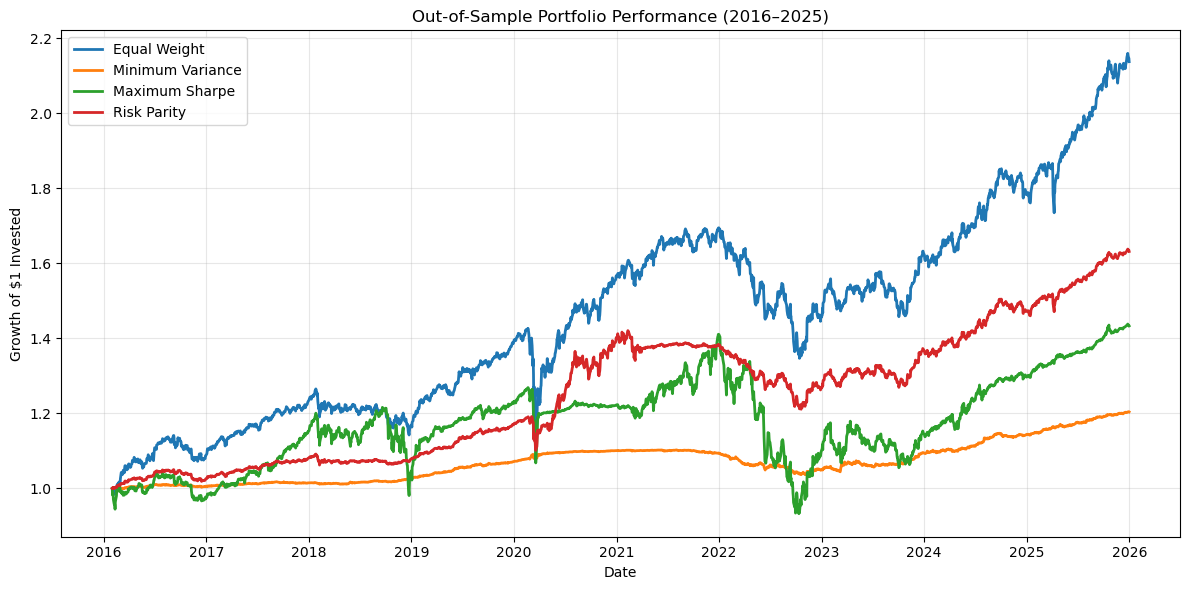

Final Value of $1 Invested
--------------------------
Equal Weight        2.1376
Minimum Variance    1.2035
Maximum Sharpe      1.4329
Risk Parity         1.6314
Name: 2025-12-31 00:00:00, dtype: float64


In [42]:

# ============================================================
# Step 6: Cumulative Out-of-Sample Performance
# ============================================================

# Calculate growth of $1 invested in each strategy
cumulative_returns = (1 + backtest_returns_df).cumprod()

# Plot cumulative portfolio performance
plt.figure(figsize=(12, 6))

for strategy in cumulative_returns.columns:
    plt.plot(
        cumulative_returns.index,
        cumulative_returns[strategy],
        label=strategy,
        linewidth=2
    )

plt.title("Out-of-Sample Portfolio Performance (2016–2025)")
plt.xlabel("Date")
plt.ylabel("Growth of $1 Invested")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Display ending portfolio values
print("Final Value of $1 Invested")
print("--------------------------")
print(cumulative_returns.iloc[-1].round(4))


In [43]:

# ============================================================
# Portfolio Risk Analysis - Step 1: Historical VaR
# ============================================================

# Set confidence level
confidence_level = 0.95

# Calculate 5th percentile of daily returns
historical_var = backtest_returns_df.quantile(
    1 - confidence_level
)

# Express VaR as a positive loss percentage
historical_var = -historical_var

# Display results
print("Historical Value at Risk (95%)")
print("-----------------------------")

for strategy, value in historical_var.items():
    print(f"{strategy}: {value:.2%}")


Historical Value at Risk (95%)
-----------------------------
Equal Weight: 0.85%
Minimum Variance: 0.13%
Maximum Sharpe: 1.10%
Risk Parity: 0.48%


In [44]:

# ============================================================
# Portfolio Risk Analysis - Step 2: Historical CVaR
# ============================================================

# Calculate Conditional Value at Risk (95%)
historical_cvar = {}

for strategy in backtest_returns_df.columns:

    # Get daily returns for the strategy
    daily_returns = backtest_returns_df[strategy]

    # Find the 5th percentile return
    var_threshold = daily_returns.quantile(0.05)

    # Select returns in the worst 5%
    worst_returns = daily_returns[
        daily_returns <= var_threshold
    ]

    # Calculate average loss in the worst 5%
    historical_cvar[strategy] = -worst_returns.mean()

# Convert results into a pandas Series
historical_cvar = pd.Series(historical_cvar)

# Display results
print("Historical Conditional Value at Risk (95%)")
print("------------------------------------------")

for strategy, value in historical_cvar.items():
    print(f"{strategy}: {value:.2%}")


Historical Conditional Value at Risk (95%)
------------------------------------------
Equal Weight: 1.37%
Minimum Variance: 0.22%
Maximum Sharpe: 1.80%
Risk Parity: 0.81%


In [45]:

# ============================================================
# Portfolio Risk Analysis - Step 3: Maximum Drawdown
# ============================================================

# Calculate cumulative portfolio growth
cumulative_returns = (1 + backtest_returns_df).cumprod()

# Calculate the highest portfolio value reached so far
running_peak = cumulative_returns.cummax()

# Calculate drawdowns from previous peaks
drawdowns = (
    cumulative_returns / running_peak
) - 1

# Calculate maximum drawdown for each portfolio
maximum_drawdown = drawdowns.min()

# Display results
print("Maximum Portfolio Drawdown")
print("--------------------------")

for strategy, value in maximum_drawdown.items():
    print(f"{strategy}: {value:.2%}")


Maximum Portfolio Drawdown
--------------------------
Equal Weight: -20.54%
Minimum Variance: -5.99%
Maximum Sharpe: -33.93%
Risk Parity: -14.76%


In [46]:

# ============================================================
# Comprehensive Portfolio Risk-Performance Summary
# ============================================================

# Combine all performance and risk metrics
portfolio_risk_summary = backtest_performance.copy()

# Add historical Value at Risk
portfolio_risk_summary["VaR (95%)"] = historical_var

# Add Conditional Value at Risk
portfolio_risk_summary["CVaR (95%)"] = historical_cvar

# Add Maximum Drawdown
portfolio_risk_summary["Maximum Drawdown"] = maximum_drawdown

# Display comprehensive results
print("Comprehensive Portfolio Risk-Performance Summary")
print("------------------------------------------------")

display(portfolio_risk_summary.round(4))


Comprehensive Portfolio Risk-Performance Summary
------------------------------------------------


,Annualized Return,Annualized Volatility,Sharpe Ratio,VaR (95%),CVaR (95%),Maximum Drawdown
Equal Weight,0.0813,0.0951,0.6443,0.0085,0.0137,-0.2054
Minimum Variance,0.0188,0.0156,-0.0749,0.0013,0.0022,-0.0599
Maximum Sharpe,0.0423,0.1094,0.2040,0.0110,0.0180,-0.3393
Risk Parity,0.0508,0.0523,0.5895,0.0048,0.0081,-0.1476


In [47]:

# ============================================================
# Monte Carlo Simulation - Step 1: Configuration
# ============================================================

# Number of simulated scenarios
num_simulations = 10000

# Number of trading days to simulate
simulation_days = 252

# Initial portfolio value
initial_investment = 10000

# Set random seed for reproducibility
np.random.seed(42)

# Estimate daily expected returns
simulation_mean_returns = backtest_returns_df.mean()

# Estimate daily covariance between strategies
simulation_covariance = backtest_returns_df.cov()

print("Monte Carlo Simulation Configuration")
print("------------------------------------")
print("Simulations:", num_simulations)
print("Trading Days:", simulation_days)
print("Initial Investment: $", initial_investment)

print("\nEstimated Daily Returns:")
display(simulation_mean_returns)

print("\nEstimated Daily Covariance Matrix:")
display(simulation_covariance)


Monte Carlo Simulation Configuration
------------------------------------
Simulations: 10000
Trading Days: 252
Initial Investment: $ 10000

Estimated Daily Returns:


Equal Weight        0.000323
Minimum Variance    0.000075
Maximum Sharpe      0.000168
Risk Parity         0.000202
dtype: float64


Estimated Daily Covariance Matrix:


,Equal Weight,Minimum Variance,Maximum Sharpe,Risk Parity
Equal Weight,0.000036,2.647226e-06,0.000027,0.000017
Minimum Variance,0.000003,9.696151e-07,0.000002,0.000002
Maximum Sharpe,0.000027,2.182860e-06,0.000047,0.000012
Risk Parity,0.000017,1.914719e-06,0.000012,0.000011


In [48]:

# ============================================================
# Monte Carlo Simulation - Step 2: Generate Simulated Returns
# ============================================================

# Create a random number generator
rng = np.random.default_rng(42)

# Generate correlated daily returns for all four strategies
simulated_returns = rng.multivariate_normal(
    mean=simulation_mean_returns.values,
    cov=simulation_covariance.values,
    size=(num_simulations, simulation_days)
)

# Calculate the growth of $10,000 over each simulation
simulated_portfolio_values = (
    initial_investment *
    np.cumprod(1 + simulated_returns, axis=1)
)

# Display the dimensions of our results
print("Monte Carlo Simulation Completed!")
print("---------------------------------")
print("Simulated Returns Shape:", simulated_returns.shape)
print("Portfolio Values Shape:", simulated_portfolio_values.shape)


Monte Carlo Simulation Completed!
---------------------------------
Simulated Returns Shape: (10000, 252, 4)
Portfolio Values Shape: (10000, 252, 4)


In [49]:

# ============================================================
# Monte Carlo Simulation - Step 3: Analyze Outcomes
# ============================================================

# Extract ending portfolio values after 252 trading days
final_portfolio_values = simulated_portfolio_values[:, -1, :]

# Create a DataFrame for easier analysis
final_values_df = pd.DataFrame(
    final_portfolio_values,
    columns=backtest_returns_df.columns
)

# Calculate summary statistics
monte_carlo_summary = pd.DataFrame({
    "Mean Ending Value": final_values_df.mean(),
    "Median Ending Value": final_values_df.median(),
    "5th Percentile": final_values_df.quantile(0.05),
    "95th Percentile": final_values_df.quantile(0.95),
    "Probability of Loss": (
        final_values_df.lt(initial_investment).mean()
    )
})

# Display results
print("Monte Carlo Simulation Results")
print("------------------------------")

display(monte_carlo_summary.round(4))


Monte Carlo Simulation Results
------------------------------


,Mean Ending Value,Median Ending Value,5th Percentile,95th Percentile,Probability of Loss
Equal Weight,10841.2462,10793.0645,9226.0790,12632.1447,0.2123
Minimum Variance,10190.4991,10190.3234,9929.2991,10458.3644,0.1159
Maximum Sharpe,10421.0225,10372.6210,8633.5549,12422.8048,0.3752
Risk Parity,10517.7333,10509.8469,9632.7177,11437.9105,0.1722


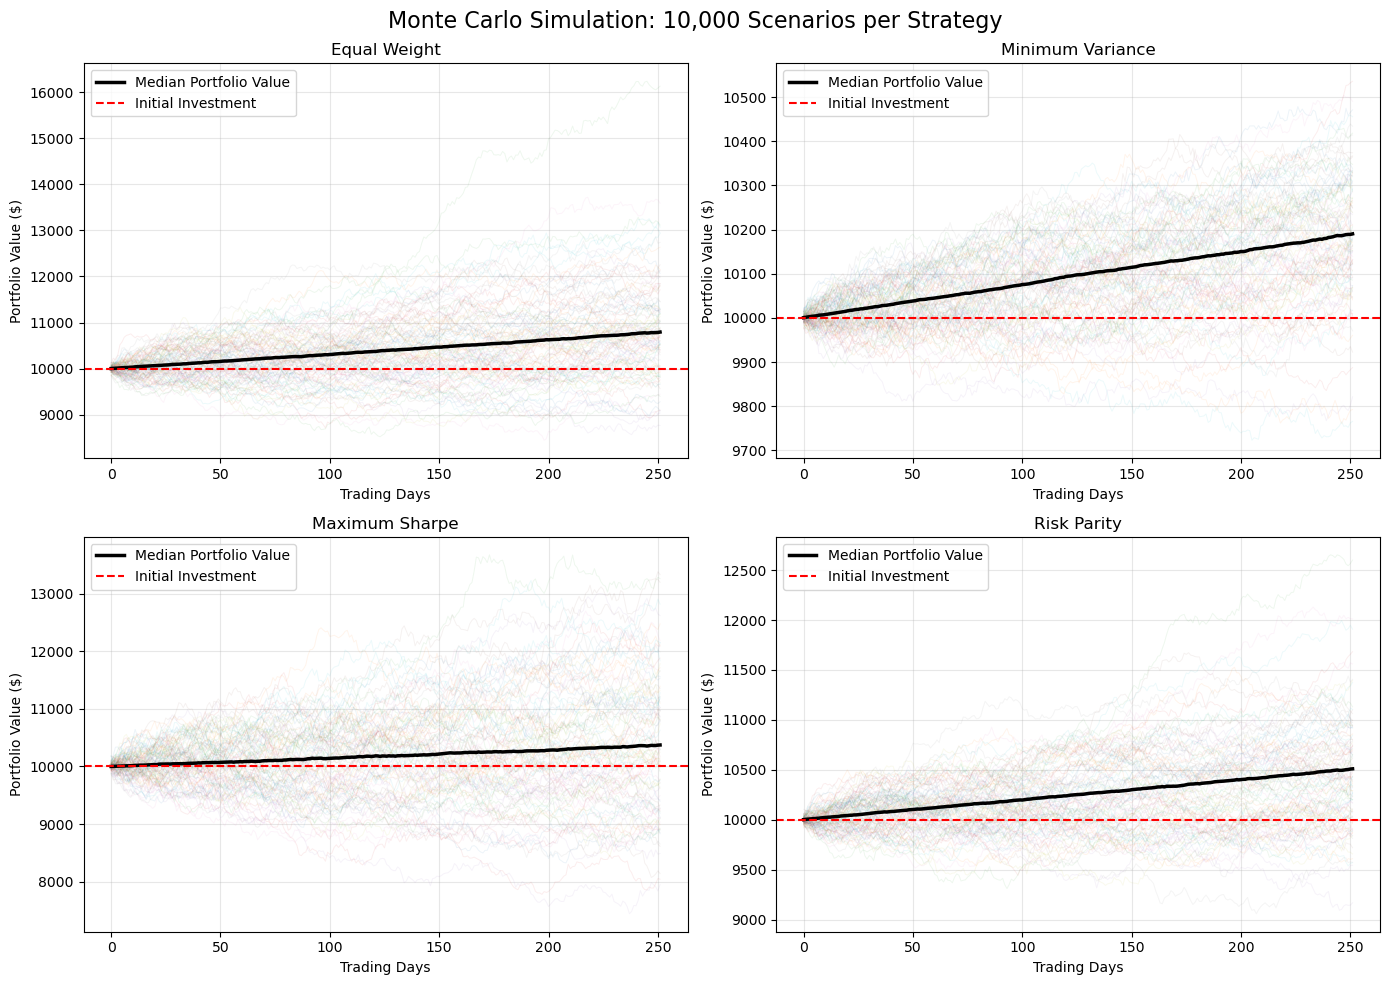

In [50]:

# ============================================================
# Monte Carlo Simulation - Step 4: Visualize Paths
# ============================================================

# Get portfolio strategy names
strategy_names = backtest_returns_df.columns

# Create a 2x2 chart layout
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Flatten axes for easier looping
axes = axes.flatten()

# Plot each strategy
for i, strategy in enumerate(strategy_names):

    # Select simulated paths for this strategy
    portfolio_paths = simulated_portfolio_values[:, :, i]

    # Plot the first 100 simulated paths
    for path in portfolio_paths[:100]:
        axes[i].plot(
            path,
            alpha=0.08,
            linewidth=0.7
        )

    # Calculate median portfolio value each day
    median_path = np.median(portfolio_paths, axis=0)

    # Plot median trajectory
    axes[i].plot(
        median_path,
        linewidth=2.5,
        color="black",
        label="Median Portfolio Value"
    )

    # Add initial investment reference
    axes[i].axhline(
        initial_investment,
        linestyle="--",
        color="red",
        label="Initial Investment"
    )

    axes[i].set_title(strategy)
    axes[i].set_xlabel("Trading Days")
    axes[i].set_ylabel("Portfolio Value ($)")
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)

plt.suptitle(
    "Monte Carlo Simulation: 10,000 Scenarios per Strategy",
    fontsize=16
)

plt.tight_layout()
plt.show()


In [51]:

# ============================================================
# Monte Carlo - Step 5: Portfolio Stress Testing
# ============================================================

# Calculate historical daily volatility
daily_volatility = backtest_returns_df.std()

# Calculate historical average daily returns
daily_mean_returns = backtest_returns_df.mean()

# Define hypothetical stress scenarios
stress_scenarios = {
    "Moderate Stress (-2σ)": 2,
    "Severe Stress (-3σ)": 3,
    "Extreme Stress (-4σ)": 4
}

# Store stress test results
stress_results = {}

for scenario, shock in stress_scenarios.items():

    # Apply a negative volatility shock
    stressed_returns = (
        daily_mean_returns - shock * daily_volatility
    )

    # Calculate dollar impact on $10,000
    stressed_values = (
        initial_investment * (1 + stressed_returns)
    )

    stress_results[scenario] = stressed_values

# Convert results into a DataFrame
stress_test_df = pd.DataFrame(stress_results)

print("Portfolio Stress Testing Results")
print("--------------------------------")

display(stress_test_df.round(2))


Portfolio Stress Testing Results
--------------------------------


,Moderate Stress (-2σ),Severe Stress (-3σ),Extreme Stress (-4σ)
Equal Weight,9883.40,9823.49,9763.58
Minimum Variance,9981.05,9971.21,9961.36
Maximum Sharpe,9863.89,9795.00,9726.10
Risk Parity,9936.18,9903.26,9870.34


In [52]:

# ============================================================
# Final Validation - Step 1: Check Backtest Data Quality
# ============================================================

print("Backtest Data Validation")
print("------------------------")

print("Missing values:")
print(backtest_returns_df.isna().sum())

print("\nDuplicate dates:",
      backtest_returns_df.index.duplicated().sum())

print("\nTrading days:",
      len(backtest_returns_df))

print("\nFirst date:",
      backtest_returns_df.index.min())

print("\nLast date:",
      backtest_returns_df.index.max())

print("\nAll returns are finite:",
      np.isfinite(backtest_returns_df.to_numpy()).all())


Backtest Data Validation
------------------------
Missing values:
Equal Weight        0
Minimum Variance    0
Maximum Sharpe      0
Risk Parity         0
dtype: int64

Duplicate dates: 0

Trading days: 2495

First date: 2016-02-01 00:00:00

Last date: 2025-12-31 00:00:00

All returns are finite: True


In [53]:

# ============================================================
# Final Validation - Step 2: Monthly Buy-and-Hold Backtest
# ============================================================

monthly_backtest = {}

for strategy, weights_df in rolling_weights_df.items():

    daily_results = []

    for i, rebalance_date in enumerate(weights_df.index):

        # Determine the next rebalancing date
        if i + 1 < len(weights_df.index):
            next_date = weights_df.index[i + 1]
        else:
            next_date = returns.index[-1]

        # Select trading days AFTER the current rebalance
        period_returns = returns.loc[
            (returns.index > rebalance_date) &
            (returns.index <= next_date)
        ]

        if period_returns.empty:
            continue

        # Portfolio weights at the start of the period
        weights = weights_df.loc[rebalance_date].to_numpy()

        # Track asset growth during the holding period
        asset_growth = (1 + period_returns).cumprod()

        # Portfolio growth with drifting weights
        portfolio_growth = asset_growth @ weights

        # Convert cumulative growth into daily returns
        period_portfolio_returns = (
            portfolio_growth /
            portfolio_growth.shift(1).fillna(1)
            - 1
        )

        daily_results.append(period_portfolio_returns)

    # Combine all holding periods
    monthly_backtest[strategy] = pd.concat(daily_results)

# Combine all strategies
monthly_backtest_df = pd.DataFrame(monthly_backtest)

print("Monthly Buy-and-Hold Backtest Completed!")
print("----------------------------------------")
print("Trading Days:", len(monthly_backtest_df))
print("Missing Values:", monthly_backtest_df.isna().sum().sum())

display(monthly_backtest_df.head())


Monthly Buy-and-Hold Backtest Completed!
----------------------------------------
Trading Days: 2495
Missing Values: 0


,Equal Weight,Minimum Variance,Maximum Sharpe,Risk Parity
Date,,,,
2016-02-01,-0.001086,-0.000528,-0.000361,-0.000712
2016-02-02,-0.008607,0.000975,-0.018022,-0.000709
2016-02-03,0.007331,0.000330,0.005995,0.001847
2016-02-04,0.003631,0.000257,0.001568,0.001473
2016-02-05,-0.005533,-0.000545,-0.019050,-0.001153


In [54]:

# ============================================================
# Final Validation - Step 3: Monthly Backtest Performance
# ============================================================

# Check data completeness
print("Trading Days:", len(monthly_backtest_df))
print("Missing Values:", monthly_backtest_df.isna().sum().sum())

# Calculate annualized returns
monthly_annual_returns = monthly_backtest_df.mean() * 252

# Calculate annualized volatility
monthly_annual_volatility = (
    monthly_backtest_df.std() * np.sqrt(252)
)

# Calculate Sharpe ratios
monthly_sharpe = (
    monthly_annual_returns - risk_free_rate
) / monthly_annual_volatility

# Calculate cumulative growth
monthly_cumulative = (1 + monthly_backtest_df).cumprod()

# Calculate maximum drawdown
monthly_drawdown = (
    monthly_cumulative / monthly_cumulative.cummax()
) - 1

# Combine results
monthly_performance = pd.DataFrame({
    "Annualized Return": monthly_annual_returns,
    "Annualized Volatility": monthly_annual_volatility,
    "Sharpe Ratio": monthly_sharpe,
    "Maximum Drawdown": monthly_drawdown.min()
})

print("\nMonthly-Rebalanced Portfolio Performance")
print("----------------------------------------")

display(monthly_performance.round(4))


Trading Days: 2495
Missing Values: 0

Monthly-Rebalanced Portfolio Performance
----------------------------------------


,Annualized Return,Annualized Volatility,Sharpe Ratio,Maximum Drawdown
Equal Weight,0.0789,0.0937,0.6284,-0.2074
Minimum Variance,0.0187,0.0156,-0.0841,-0.0600
Maximum Sharpe,0.0413,0.1090,0.1956,-0.3409
Risk Parity,0.0497,0.0518,0.5730,-0.1487


In [55]:

# ============================================================
# Final Validation - Step 4: Updated Risk Metrics
# ============================================================

# Calculate 95% historical Value at Risk
monthly_var = -monthly_backtest_df.quantile(0.05)

# Calculate 95% historical Conditional Value at Risk
monthly_cvar = {}

for strategy in monthly_backtest_df.columns:

    daily_returns = monthly_backtest_df[strategy]

    threshold = daily_returns.quantile(0.05)

    worst_returns = daily_returns[
        daily_returns <= threshold
    ]

    monthly_cvar[strategy] = -worst_returns.mean()

monthly_cvar = pd.Series(monthly_cvar)

# Update comprehensive performance table
final_performance = monthly_performance.copy()

final_performance["VaR (95%)"] = monthly_var

final_performance["CVaR (95%)"] = monthly_cvar

print("Updated Portfolio Risk-Performance Summary")
print("------------------------------------------")

display(final_performance.round(4))


Updated Portfolio Risk-Performance Summary
------------------------------------------


,Annualized Return,Annualized Volatility,Sharpe Ratio,Maximum Drawdown,VaR (95%),CVaR (95%)
Equal Weight,0.0789,0.0937,0.6284,-0.2074,0.0085,0.0136
Minimum Variance,0.0187,0.0156,-0.0841,-0.0600,0.0013,0.0022
Maximum Sharpe,0.0413,0.1090,0.1956,-0.3409,0.0110,0.0180
Risk Parity,0.0497,0.0518,0.5730,-0.1487,0.0047,0.0080


In [56]:

# ============================================================
# Final Validation - Step 5: Updated Monte Carlo Simulation
# ============================================================

# Set simulation parameters
num_simulations = 10000
simulation_days = 252
initial_investment = 10000

# Estimate returns and covariance from monthly backtest
simulation_mean_returns = monthly_backtest_df.mean()
simulation_covariance = monthly_backtest_df.cov()

# Initialize random number generator
rng = np.random.default_rng(42)

# Generate correlated simulated returns
simulated_returns = rng.multivariate_normal(
    mean=simulation_mean_returns.values,
    cov=simulation_covariance.values,
    size=(num_simulations, simulation_days)
)

# Calculate simulated portfolio values
simulated_portfolio_values = (
    initial_investment *
    np.cumprod(1 + simulated_returns, axis=1)
)

# Extract ending values
final_portfolio_values = simulated_portfolio_values[:, -1, :]

# Convert into DataFrame
final_values_df = pd.DataFrame(
    final_portfolio_values,
    columns=monthly_backtest_df.columns
)

# Calculate simulation statistics
monte_carlo_summary = pd.DataFrame({
    "Mean Ending Value": final_values_df.mean(),
    "Median Ending Value": final_values_df.median(),
    "5th Percentile": final_values_df.quantile(0.05),
    "95th Percentile": final_values_df.quantile(0.95),
    "Probability of Loss": (
        final_values_df.lt(initial_investment).mean()
    )
})

print("Updated Monte Carlo Simulation Results")
print("--------------------------------------")

display(monte_carlo_summary.round(4))


Updated Monte Carlo Simulation Results
--------------------------------------


,Mean Ending Value,Median Ending Value,5th Percentile,95th Percentile,Probability of Loss
Equal Weight,10815.6443,10767.6696,9225.1457,12574.0957,0.2160
Minimum Variance,10189.1099,10188.9479,9929.3349,10455.2094,0.1162
Maximum Sharpe,10410.7928,10361.3978,8631.2383,12403.2359,0.3783
Risk Parity,10505.7374,10498.0523,9630.3608,11414.8621,0.1760


In [57]:

# ============================================================
# Final Validation - Step 6: Economic Stress Scenarios
# ============================================================

# Hypothetical one-period ETF returns under three scenarios
economic_scenarios = pd.DataFrame({

    "Equity Market Crash": {
        "SPY": -0.30,
        "VXUS": -0.28,
        "VWO": -0.35,
        "IEF": 0.08,
        "LQD": -0.08,
        "VNQ": -0.25,
        "GLD": 0.10,
        "SHY": 0.01
    },

    "Interest Rate Shock": {
        "SPY": -0.10,
        "VXUS": -0.12,
        "VWO": -0.15,
        "IEF": -0.12,
        "LQD": -0.10,
        "VNQ": -0.18,
        "GLD": -0.05,
        "SHY": -0.01
    },

    "Inflation Shock": {
        "SPY": -0.15,
        "VXUS": -0.12,
        "VWO": -0.18,
        "IEF": -0.10,
        "LQD": -0.08,
        "VNQ": -0.12,
        "GLD": 0.15,
        "SHY": 0.00
    }

})

# Use the latest available portfolio target weights
latest_weights = pd.DataFrame({
    strategy: weights_df.iloc[-1]
    for strategy, weights_df in rolling_weights_df.items()
}).T

# Align ETF columns before multiplication
latest_weights = latest_weights[economic_scenarios.index]

# Calculate portfolio returns under each scenario
economic_stress_results = (
    latest_weights @ economic_scenarios
)

print("Economic Stress Testing Results")
print("--------------------------------")
display((economic_stress_results * 100).round(2))


Economic Stress Testing Results
--------------------------------


,Equity Market Crash,Interest Rate Shock,Inflation Shock
Equal Weight,-13.37,-10.38,-7.50
Minimum Variance,0.38,-1.21,-0.30
Maximum Sharpe,0.09,-1.82,0.35
Risk Parity,-2.96,-5.32,-3.43


In [58]:

# ============================================================
# Final Validation - Step 7: Portfolio Turnover Analysis
# ============================================================

turnover_results = {}

for strategy, weights_df in rolling_weights_df.items():

    # Previous target weights
    previous_weights = weights_df.shift(1)

    # Absolute change in ETF allocations
    weight_changes = (
        weights_df - previous_weights
    ).abs()

    # One-way turnover approximation
    monthly_turnover = weight_changes.sum(axis=1) / 2

    # Exclude first observation
    monthly_turnover = monthly_turnover.iloc[1:]

    # Store turnover statistics
    turnover_results[strategy] = {
        "Average Monthly Turnover": monthly_turnover.mean(),
        "Annualized Turnover": monthly_turnover.mean() * 12,
        "Maximum Monthly Turnover": monthly_turnover.max()
    }

# Create summary table
turnover_summary = pd.DataFrame(turnover_results).T

print("Portfolio Turnover Analysis")
print("---------------------------")

display((turnover_summary * 100).round(2))


Portfolio Turnover Analysis
---------------------------


,Average Monthly Turnover,Annualized Turnover,Maximum Monthly Turnover
Equal Weight,0.00,0.00,0.00
Minimum Variance,0.39,4.67,4.48
Maximum Sharpe,27.39,328.65,100.00
Risk Parity,2.88,34.53,91.08


In [59]:

# ============================================================
# Final Validation - Step 8: Actual Rebalancing Turnover
# ============================================================

actual_turnover_results = {}
turnover_by_strategy = {}

for strategy, weights_df in rolling_weights_df.items():

    turnover_values = []

    for i in range(1, len(weights_df)):

        previous_date = weights_df.index[i - 1]
        current_date = weights_df.index[i]

        # Weights immediately after the previous rebalance
        previous_weights = weights_df.iloc[i - 1]

        # ETF returns between rebalancing dates
        holding_returns = returns.loc[
            (returns.index > previous_date) &
            (returns.index <= current_date)
        ]

        # Growth of each ETF
        asset_growth = (1 + holding_returns).prod()

        # Weights after market movements, before rebalancing
        drifted_weights = previous_weights * asset_growth
        drifted_weights = drifted_weights / drifted_weights.sum()

        # New target allocation
        target_weights = weights_df.iloc[i]

        # Actual one-way turnover
        turnover = (
            target_weights - drifted_weights
        ).abs().sum() / 2

        turnover_values.append(turnover)

    turnover_series = pd.Series(
        turnover_values,
        index=weights_df.index[1:]
    )

    turnover_by_strategy[strategy] = turnover_series

    actual_turnover_results[strategy] = {
        "Average Monthly Turnover": turnover_series.mean(),
        "Annualized Turnover": turnover_series.mean() * 12,
        "Maximum Monthly Turnover": turnover_series.max()
    }

actual_turnover_summary = pd.DataFrame(
    actual_turnover_results
).T

print("Actual Portfolio Rebalancing Turnover")
print("------------------------------------")

display((actual_turnover_summary * 100).round(2))


Actual Portfolio Rebalancing Turnover
------------------------------------


,Average Monthly Turnover,Annualized Turnover,Maximum Monthly Turnover
Equal Weight,1.00,11.95,4.34
Minimum Variance,0.38,4.57,4.66
Maximum Sharpe,27.21,326.54,100.00
Risk Parity,2.98,35.82,91.08


In [60]:

# ============================================================
# Final Validation - Step 9: Transaction Cost Sensitivity
# ============================================================

# Transaction cost rates per dollar traded
transaction_cost_rates = {
    "5 bps": 0.0005,
    "10 bps": 0.0010,
    "25 bps": 0.0025
}

net_performance_results = {}

for cost_label, cost_rate in transaction_cost_rates.items():

    # Start with gross portfolio returns
    net_returns = monthly_backtest_df.copy()

    for strategy in net_returns.columns:

        # Retrieve monthly rebalancing turnover
        turnover_series = turnover_by_strategy[strategy]

        # Cost as a fraction of portfolio value
        # One-way turnover counts purchases or sales,
        # so multiply by 2 for total traded value
        trading_costs = 2 * turnover_series * cost_rate

        # Apply costs on rebalancing dates
        for date, cost in trading_costs.items():

            if date in net_returns.index:

                gross_return = net_returns.loc[date, strategy]

                # Deduct costs multiplicatively
                net_returns.loc[date, strategy] = (
                    (1 + gross_return) * (1 - cost) - 1
                )

    # Annualized return after transaction costs
    annual_net_return = net_returns.mean() * 252

    # Annualized volatility after transaction costs
    annual_net_volatility = (
        net_returns.std() * np.sqrt(252)
    )

    # Net Sharpe ratio
    net_sharpe = (
        annual_net_return - risk_free_rate
    ) / annual_net_volatility

    for strategy in net_returns.columns:

        net_performance_results[(strategy, cost_label)] = {
            "Net Annualized Return": annual_net_return[strategy],
            "Net Sharpe Ratio": net_sharpe[strategy]
        }

# Combine results
transaction_cost_summary = pd.DataFrame(
    net_performance_results
).T

print("Transaction Cost Sensitivity Analysis")
print("-------------------------------------")

display(transaction_cost_summary.round(4))


Transaction Cost Sensitivity Analysis
-------------------------------------


,,Net Annualized Return,Net Sharpe Ratio
Equal Weight,5 bps,0.0788,0.6271
Minimum Variance,5 bps,0.0186,-0.0871
Maximum Sharpe,5 bps,0.0381,0.1656
Risk Parity,5 bps,0.0493,0.5661
Equal Weight,10 bps,0.0787,0.6258
Minimum Variance,10 bps,0.0186,-0.0900
Maximum Sharpe,10 bps,0.0348,0.1356
Risk Parity,10 bps,0.0489,0.5592
Equal Weight,25 bps,0.0783,0.6220
Minimum Variance,25 bps,0.0185,-0.0988


In [61]:

# ============================================================
# Final Reporting - Step 2: Investment Performance Summary
# ============================================================

# Select net performance under 10 bps trading costs
net_10bps = transaction_cost_summary.xs(
    "10 bps", level=1
)

# Build final comparison table
investment_summary = pd.DataFrame({

    "Gross Return (%)":
        final_performance["Annualized Return"] * 100,

    "Net Return 10bps (%)":
        net_10bps["Net Annualized Return"] * 100,

    "Volatility (%)":
        final_performance["Annualized Volatility"] * 100,

    "Gross Sharpe":
        final_performance["Sharpe Ratio"],

    "Net Sharpe 10bps":
        net_10bps["Net Sharpe Ratio"],

    "Max Drawdown (%)":
        final_performance["Maximum Drawdown"] * 100,

    "Annual Turnover (%)":
        actual_turnover_summary["Annualized Turnover"] * 100

})

print("FINAL INVESTMENT PERFORMANCE COMPARISON")
print("---------------------------------------")

display(investment_summary.round(2))


FINAL INVESTMENT PERFORMANCE COMPARISON
---------------------------------------


,Gross Return (%),Net Return 10bps (%),Volatility (%),Gross Sharpe,Net Sharpe 10bps,Max Drawdown (%),Annual Turnover (%)
Equal Weight,7.89,7.87,9.37,0.63,0.63,-20.74,11.95
Minimum Variance,1.87,1.86,1.56,-0.08,-0.09,-6.00,4.57
Maximum Sharpe,4.13,3.48,10.90,0.20,0.14,-34.09,326.54
Risk Parity,4.97,4.89,5.18,0.57,0.56,-14.87,35.82


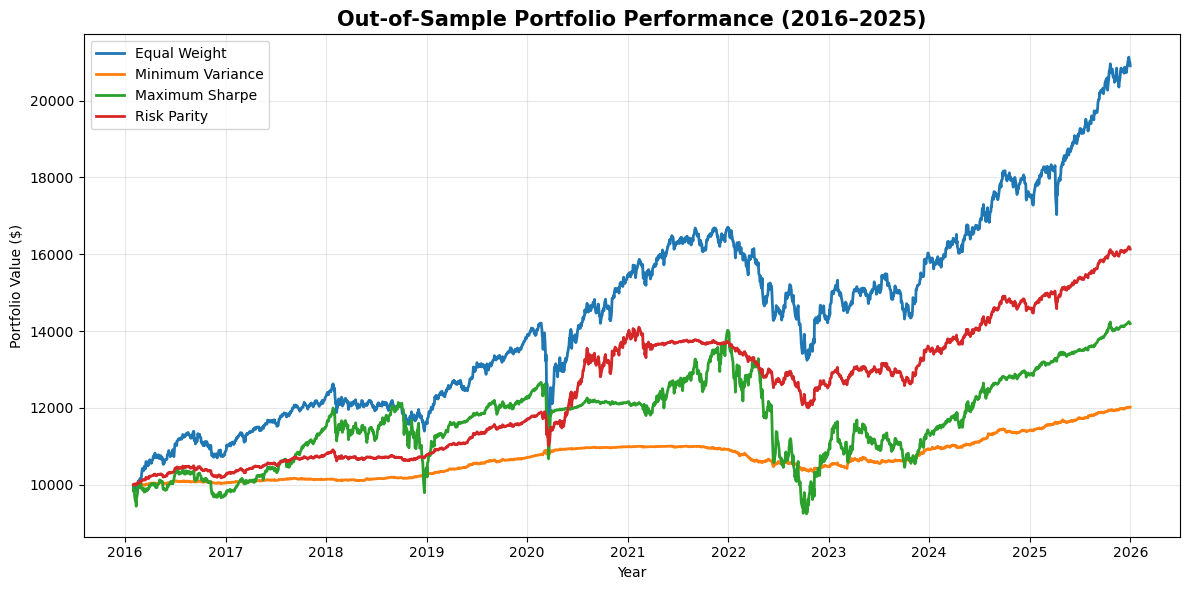

In [62]:

# ============================================================
# Final Reporting - Step 3: Cumulative Portfolio Performance
# ============================================================

# Calculate growth of $10,000
portfolio_growth = (
    10000 * (1 + monthly_backtest_df).cumprod()
)

# Create chart
plt.figure(figsize=(12, 6))

for strategy in portfolio_growth.columns:
    plt.plot(
        portfolio_growth.index,
        portfolio_growth[strategy],
        label=strategy,
        linewidth=2
    )

plt.title(
    "Out-of-Sample Portfolio Performance (2016–2025)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Year")
plt.ylabel("Portfolio Value ($)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save high-resolution chart
plt.savefig(
    "portfolio_cumulative_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


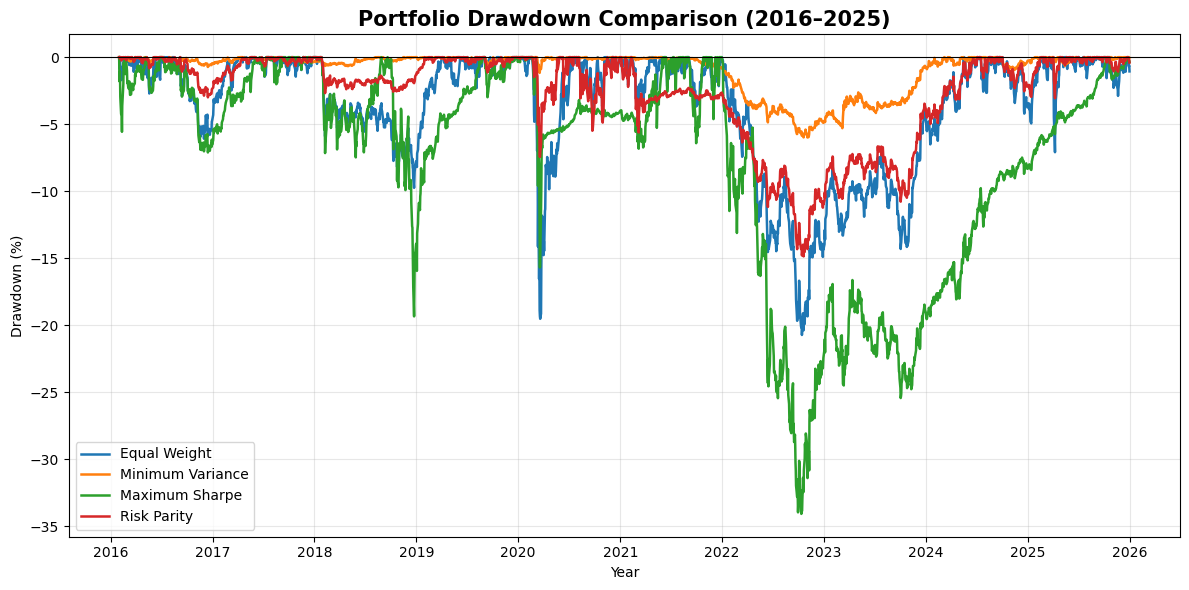

In [63]:

# ============================================================
# Final Reporting - Step 4: Portfolio Drawdown Comparison
# ============================================================

# Calculate cumulative portfolio wealth
cumulative_wealth = (
    1 + monthly_backtest_df
).cumprod()

# Calculate running portfolio peaks
running_peaks = cumulative_wealth.cummax()

# Calculate drawdowns
drawdown_df = (
    cumulative_wealth / running_peaks - 1
) * 100

# Create drawdown chart
plt.figure(figsize=(12, 6))

for strategy in drawdown_df.columns:

    plt.plot(
        drawdown_df.index,
        drawdown_df[strategy],
        label=strategy,
        linewidth=1.8
    )

plt.axhline(0, color="black", linewidth=0.8)

plt.title(
    "Portfolio Drawdown Comparison (2016–2025)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Year")
plt.ylabel("Drawdown (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save chart
plt.savefig(
    "portfolio_drawdown_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [64]:

# ============================================================
# Final Reporting - Step 5: Export Project Results
# ============================================================

from pathlib import Path

# Create project output folders
output_folder = Path("outputs")
charts_folder = output_folder / "charts"
tables_folder = output_folder / "tables"

charts_folder.mkdir(parents=True, exist_ok=True)
tables_folder.mkdir(parents=True, exist_ok=True)

# Export final investment comparison
investment_summary.to_csv(
    tables_folder / "investment_performance_summary.csv"
)

# Export historical risk metrics
final_performance.to_csv(
    tables_folder / "portfolio_risk_metrics.csv"
)

# Export Monte Carlo simulation results
monte_carlo_summary.to_csv(
    tables_folder / "monte_carlo_summary.csv"
)

# Export economic stress testing
economic_stress_results.to_csv(
    tables_folder / "economic_stress_results.csv"
)

# Export turnover analysis
actual_turnover_summary.to_csv(
    tables_folder / "portfolio_turnover_summary.csv"
)

# Export transaction-cost analysis
transaction_cost_summary.to_csv(
    tables_folder / "transaction_cost_sensitivity.csv"
)

# Export daily portfolio returns
monthly_backtest_df.to_csv(
    tables_folder / "portfolio_daily_returns.csv"
)

# Copy existing charts into outputs/charts
import shutil

for chart_name in [
    "portfolio_cumulative_performance.png",
    "portfolio_drawdown_comparison.png"
]:
    source = Path(chart_name)
    destination = charts_folder / chart_name

    if source.exists():
        shutil.copy2(source, destination)
        print("Saved:", destination)
    else:
        print("Chart not found:", source)

print("\nAll available project results exported successfully!")


Saved: outputs\charts\portfolio_cumulative_performance.png
Saved: outputs\charts\portfolio_drawdown_comparison.png

All available project results exported successfully!


In [66]:

# Create requirements.txt

requirements = [
    "numpy",
    "pandas",
    "scipy",
    "matplotlib",
    "yfinance",
    "jupyter"
]

with open("requirements.txt", "w") as file:
    file.write("\n".join(requirements) + "\n")

print("requirements.txt created successfully!")



requirements.txt created successfully!


In [67]:

# Create .gitignore

gitignore = """
.ipynb_checkpoints/
__pycache__/
*.pyc
.env
.venv/
"""

with open(".gitignore", "w") as file:
    file.write(gitignore.strip() + "\n")

print(".gitignore created successfully!")


.gitignore created successfully!


In [68]:

from pathlib import Path

readme = """# Multi-Asset Portfolio Analytics Platform

**Python | Portfolio Optimization | Quantitative Risk Management | Monte Carlo Simulation | Backtesting**

## Project Overview

Developed a Python-based multi-asset portfolio analytics platform to evaluate portfolio construction, risk-adjusted performance, downside risk and implementation costs across four investment strategies.

The analysis covers eight exchange-traded funds (ETFs) representing U.S. equities, international equities, emerging markets, fixed income, real estate and gold.

Four portfolio strategies were evaluated:

- Equal Weight
- Minimum Variance
- Maximum Sharpe Ratio
- Risk Parity

## Methodology

- **Data:** Historical adjusted ETF prices from Yahoo Finance, covering 2015–2025.
- **Portfolio optimization:** Long-only portfolio allocations subject to full-investment constraints.
- **Backtesting:** 252-trading-day rolling estimation windows, monthly portfolio rebalancing and out-of-sample evaluation from February 2016 through December 2025.
- **Risk management:** Annualized volatility, Sharpe ratio, historical Value at Risk (VaR), Conditional Value at Risk (CVaR) and maximum drawdown.
- **Monte Carlo simulation:** 10,000 correlated return scenarios over a 252-trading-day horizon.
- **Stress testing:** Hypothetical equity-market, interest-rate and inflation shocks.
- **Implementation analysis:** Portfolio turnover and transaction-cost sensitivity at 5, 10 and 25 basis points per dollar traded.

## Key Results

| Strategy         | Gross Return | Net Return (10 bps) | Volatility | Max Drawdown |
| ---------------- | ------------ | ------------------- | ---------- | ------------ |
| Equal Weight     | 7.89%        | 7.87%               | 9.37%      | -20.74%      |
| Minimum Variance | 1.87%        | 1.86%               | 1.56%      | -6.00%       |
| Maximum Sharpe   | 4.13%        | 3.48%               | 10.90%     | -34.09%      |
| Risk Parity      | 4.97%        | 4.89%               | 5.18%      | -14.87%      |

Returns are annualized. Net returns reflect illustrative transaction costs.

## Key Investment Findings

**1. Equal Weight outperformed optimized strategies.**

The Equal Weight portfolio generated the highest out-of-sample annualized return (7.89%) and Sharpe ratio (0.63), highlighting the potential limitations of optimization based on historical estimates.

**2. Maximum Sharpe exhibited substantial implementation costs.**

The Maximum Sharpe strategy generated 326.54% annualized one-way turnover. Its annualized return declined from 4.13% gross to 3.48% net under the 10-basis-point transaction-cost assumption.

**3. Minimum Variance delivered the strongest downside protection.**

The strategy experienced 1.56% annualized volatility and a maximum historical drawdown of 6.00%, although its return was relatively low.

**4. Risk Parity provided a defensive alternative.**

Risk Parity generated a 4.97% gross annualized return with 5.18% volatility and a maximum drawdown of 14.87%.

## Monte Carlo Simulation

Simulated 10,000 potential one-year return paths for each portfolio using historically estimated mean returns and covariance.

The estimated probabilities of ending below the initial investment were:

| Strategy         | Simulated Probability of Loss |
| ---------------- | ----------------------------- |
| Equal Weight     | 21.60%                        |
| Minimum Variance | 11.62%                        |
| Maximum Sharpe   | 37.83%                        |
| Risk Parity      | 17.60%                        |

## Limitations

The analysis excludes taxes, market impact and financing costs. Transaction costs are modeled using illustrative assumptions. Monte Carlo simulations assume normally distributed returns with fixed historical parameters. Historical and simulated performance do not guarantee future results.

## Technologies

Python, Pandas, NumPy, SciPy, Matplotlib, Jupyter Notebook and Yahoo Finance market data.

## Conclusion

The project demonstrates that sophisticated portfolio optimization does not necessarily outperform simpler allocation strategies out of sample. Robust investment analysis requires evaluating return, volatility, downside exposure, portfolio turnover and transaction costs together.
"""

Path("README.md").write_text(readme, encoding="utf-8")

print("README.md created successfully!")


README.md created successfully!


In [69]:

# Verify project files before GitHub upload

from pathlib import Path

print("CURRENT PROJECT FOLDER:")
print(Path.cwd())

print("\nPROJECT FILES:")
print("---------------------------")

for file in sorted(Path.cwd().rglob("*")):
    if file.is_file() and ".ipynb_checkpoints" not in file.parts:
        print(file.relative_to(Path.cwd()))


CURRENT PROJECT FOLDER:
C:\Users\brady\OneDrive\Desktop\multi-asset _portfolio analytics_platform\notebooks

PROJECT FILES:
---------------------------
.gitignore
outputs\charts\portfolio_cumulative_performance.png
outputs\charts\portfolio_drawdown_comparison.png
outputs\tables\economic_stress_results.csv
outputs\tables\investment_performance_summary.csv
outputs\tables\monte_carlo_summary.csv
outputs\tables\portfolio_daily_returns.csv
outputs\tables\portfolio_risk_metrics.csv
outputs\tables\portfolio_turnover_summary.csv
outputs\tables\transaction_cost_sensitivity.csv
portfolio_analytics.ipynb
portfolio_cumulative_performance.png
portfolio_drawdown_comparison.png
README.md
requirements.txt


In [70]:

# Organize files for GitHub

from pathlib import Path
import shutil

# Current notebooks folder
notebooks_folder = Path.cwd()

# Main project folder
project_folder = notebooks_folder.parent

# Files to move to main project folder
files_to_move = [
    "README.md",
    "requirements.txt",
    ".gitignore"
]

for filename in files_to_move:
    source = notebooks_folder / filename
    destination = project_folder / filename

    if source.exists():
        shutil.move(str(source), str(destination))
        print("Moved:", filename)

# Move outputs folder
source_outputs = notebooks_folder / "outputs"
destination_outputs = project_folder / "outputs"

if source_outputs.exists():
    if destination_outputs.exists():
        print("Outputs destination already exists; not moving.")
    else:
        shutil.move(
            str(source_outputs),
            str(destination_outputs)
        )
        print("Moved: outputs folder")

print("\nProject organization completed!")


Moved: README.md
Moved: requirements.txt
Moved: .gitignore
Outputs destination already exists; not moving.

Project organization completed!


In [71]:

# Verify final GitHub project structure

from pathlib import Path

project_folder = Path.cwd().parent

print("MAIN PROJECT FOLDER:")
print(project_folder)

print("\nPROJECT FILES:")
print("----------------------------")

for file in sorted(project_folder.rglob("*")):
    if file.is_file() and not any(
        part in {".ipynb_checkpoints", ".git", "__pycache__"}
        for part in file.parts
    ):
        print(file.relative_to(project_folder))


MAIN PROJECT FOLDER:
C:\Users\brady\OneDrive\Desktop\multi-asset _portfolio analytics_platform

PROJECT FILES:
----------------------------
.gitignore
notebooks\outputs\charts\portfolio_cumulative_performance.png
notebooks\outputs\charts\portfolio_drawdown_comparison.png
notebooks\outputs\tables\economic_stress_results.csv
notebooks\outputs\tables\investment_performance_summary.csv
notebooks\outputs\tables\monte_carlo_summary.csv
notebooks\outputs\tables\portfolio_daily_returns.csv
notebooks\outputs\tables\portfolio_risk_metrics.csv
notebooks\outputs\tables\portfolio_turnover_summary.csv
notebooks\outputs\tables\transaction_cost_sensitivity.csv
notebooks\portfolio_analytics.ipynb
notebooks\portfolio_cumulative_performance.png
notebooks\portfolio_drawdown_comparison.png
README.md\README.md
requirements.txt


In [72]:

# Fix GitHub project folder structure

from pathlib import Path
import shutil

project = Path.cwd().parent
notebooks = project / "notebooks"

# 1. Fix README.md location
readme_folder = project / "README.md"
readme_file = readme_folder / "README.md"

if readme_file.is_file():
    shutil.move(
        str(readme_file),
        str(project / "README.md_temp")
    )

    readme_folder.rmdir()

    (project / "README.md_temp").rename(
        project / "README.md"
    )

    print("README.md fixed!")

# 2. Move outputs to main project folder
source = notebooks / "outputs"
destination = project / "outputs"

if source.is_dir() and not destination.exists():
    shutil.move(str(source), str(destination))
    print("Outputs folder moved!")

# 3. Remove duplicate chart files from notebooks
for filename in [
    "portfolio_cumulative_performance.png",
    "portfolio_drawdown_comparison.png"
]:
    duplicate = notebooks / filename

    if duplicate.exists():
        duplicate.unlink()
        print("Removed duplicate:", filename)

print("\nProject folder organization completed!")


README.md fixed!
Removed duplicate: portfolio_cumulative_performance.png
Removed duplicate: portfolio_drawdown_comparison.png

Project folder organization completed!


In [73]:

from pathlib import Path

project = Path.cwd().parent

print("FINAL PROJECT STRUCTURE")
print("-----------------------")

for file in sorted(project.rglob("*")):
    if file.is_file() and ".ipynb_checkpoints" not in file.parts:
        print(file.relative_to(project))

print("\nCHECKS")
print("README:", (project / "README.md").is_file())
print("Notebook:", (project / "notebooks" / "portfolio_analytics.ipynb").is_file())
print("Charts:", len(list((project / "outputs" / "charts").glob("*.png"))))
print("CSV tables:", len(list((project / "outputs" / "tables").glob("*.csv"))))


FINAL PROJECT STRUCTURE
-----------------------
.gitignore
notebooks\outputs\charts\portfolio_cumulative_performance.png
notebooks\outputs\charts\portfolio_drawdown_comparison.png
notebooks\outputs\tables\economic_stress_results.csv
notebooks\outputs\tables\investment_performance_summary.csv
notebooks\outputs\tables\monte_carlo_summary.csv
notebooks\outputs\tables\portfolio_daily_returns.csv
notebooks\outputs\tables\portfolio_risk_metrics.csv
notebooks\outputs\tables\portfolio_turnover_summary.csv
notebooks\outputs\tables\transaction_cost_sensitivity.csv
notebooks\portfolio_analytics.ipynb
README.md
requirements.txt

CHECKS
README: True
Notebook: True
Charts: 0
CSV tables: 0


In [74]:

# Move outputs to the main project folder

from pathlib import Path
import shutil

project = Path.cwd().parent

source = project / "notebooks" / "outputs"
destination = project / "outputs"

if source.is_dir() and not destination.exists():
    shutil.move(str(source), str(destination))
    print("Outputs folder moved successfully!")

elif destination.exists():
    print("Destination already exists. No files moved.")

else:
    print("Source outputs folder not found.")

# Verify the results
print("\nFINAL CHECKS")
print("README:", (project / "README.md").is_file())
print("Notebook:", (project / "notebooks" / "portfolio_analytics.ipynb").is_file())
print("Charts:", len(list((project / "outputs" / "charts").glob("*.png"))))
print("CSV tables:", len(list((project / "outputs" / "tables").glob("*.csv"))))


Destination already exists. No files moved.

FINAL CHECKS
README: True
Notebook: True
Charts: 0
CSV tables: 0


In [75]:

from pathlib import Path
import shutil

# Define folders
project = Path.cwd().parent

source = project / "notebooks" / "outputs"
destination = project / "outputs"

# Move charts and tables into the main outputs folder
for folder_name in ["charts", "tables"]:

    source_folder = source / folder_name
    destination_folder = destination / folder_name

    destination_folder.mkdir(parents=True, exist_ok=True)

    if source_folder.exists():

        for file in source_folder.iterdir():

            if file.is_file():
                shutil.copy2(
                    file,
                    destination_folder / file.name
                )

                print("Copied:", file.name)

# Verify results
print("\nFINAL CHECKS")
print("README:", (project / "README.md").is_file())
print("Notebook:", (project / "notebooks" / "portfolio_analytics.ipynb").is_file())
print("Charts:", len(list((destination / "charts").glob("*.png"))))
print("CSV tables:", len(list((destination / "tables").glob("*.csv"))))


Copied: portfolio_cumulative_performance.png
Copied: portfolio_drawdown_comparison.png
Copied: economic_stress_results.csv
Copied: investment_performance_summary.csv
Copied: monte_carlo_summary.csv
Copied: portfolio_daily_returns.csv
Copied: portfolio_risk_metrics.csv
Copied: portfolio_turnover_summary.csv
Copied: transaction_cost_sensitivity.csv

FINAL CHECKS
README: True
Notebook: True
Charts: 2
CSV tables: 7


In [76]:

# Set permanent project output paths

from pathlib import Path

# Main project directory
project_folder = Path.cwd().parent

# Output directories
output_folder = project_folder / "outputs"
charts_folder = output_folder / "charts"
tables_folder = output_folder / "tables"

# Ensure directories exist
charts_folder.mkdir(parents=True, exist_ok=True)
tables_folder.mkdir(parents=True, exist_ok=True)

print("Project folder:", project_folder)
print("Charts folder:", charts_folder)
print("Tables folder:", tables_folder)

print("\nOutput paths configured successfully!")


Project folder: C:\Users\brady\OneDrive\Desktop\multi-asset _portfolio analytics_platform
Charts folder: C:\Users\brady\OneDrive\Desktop\multi-asset _portfolio analytics_platform\outputs\charts
Tables folder: C:\Users\brady\OneDrive\Desktop\multi-asset _portfolio analytics_platform\outputs\tables

Output paths configured successfully!
